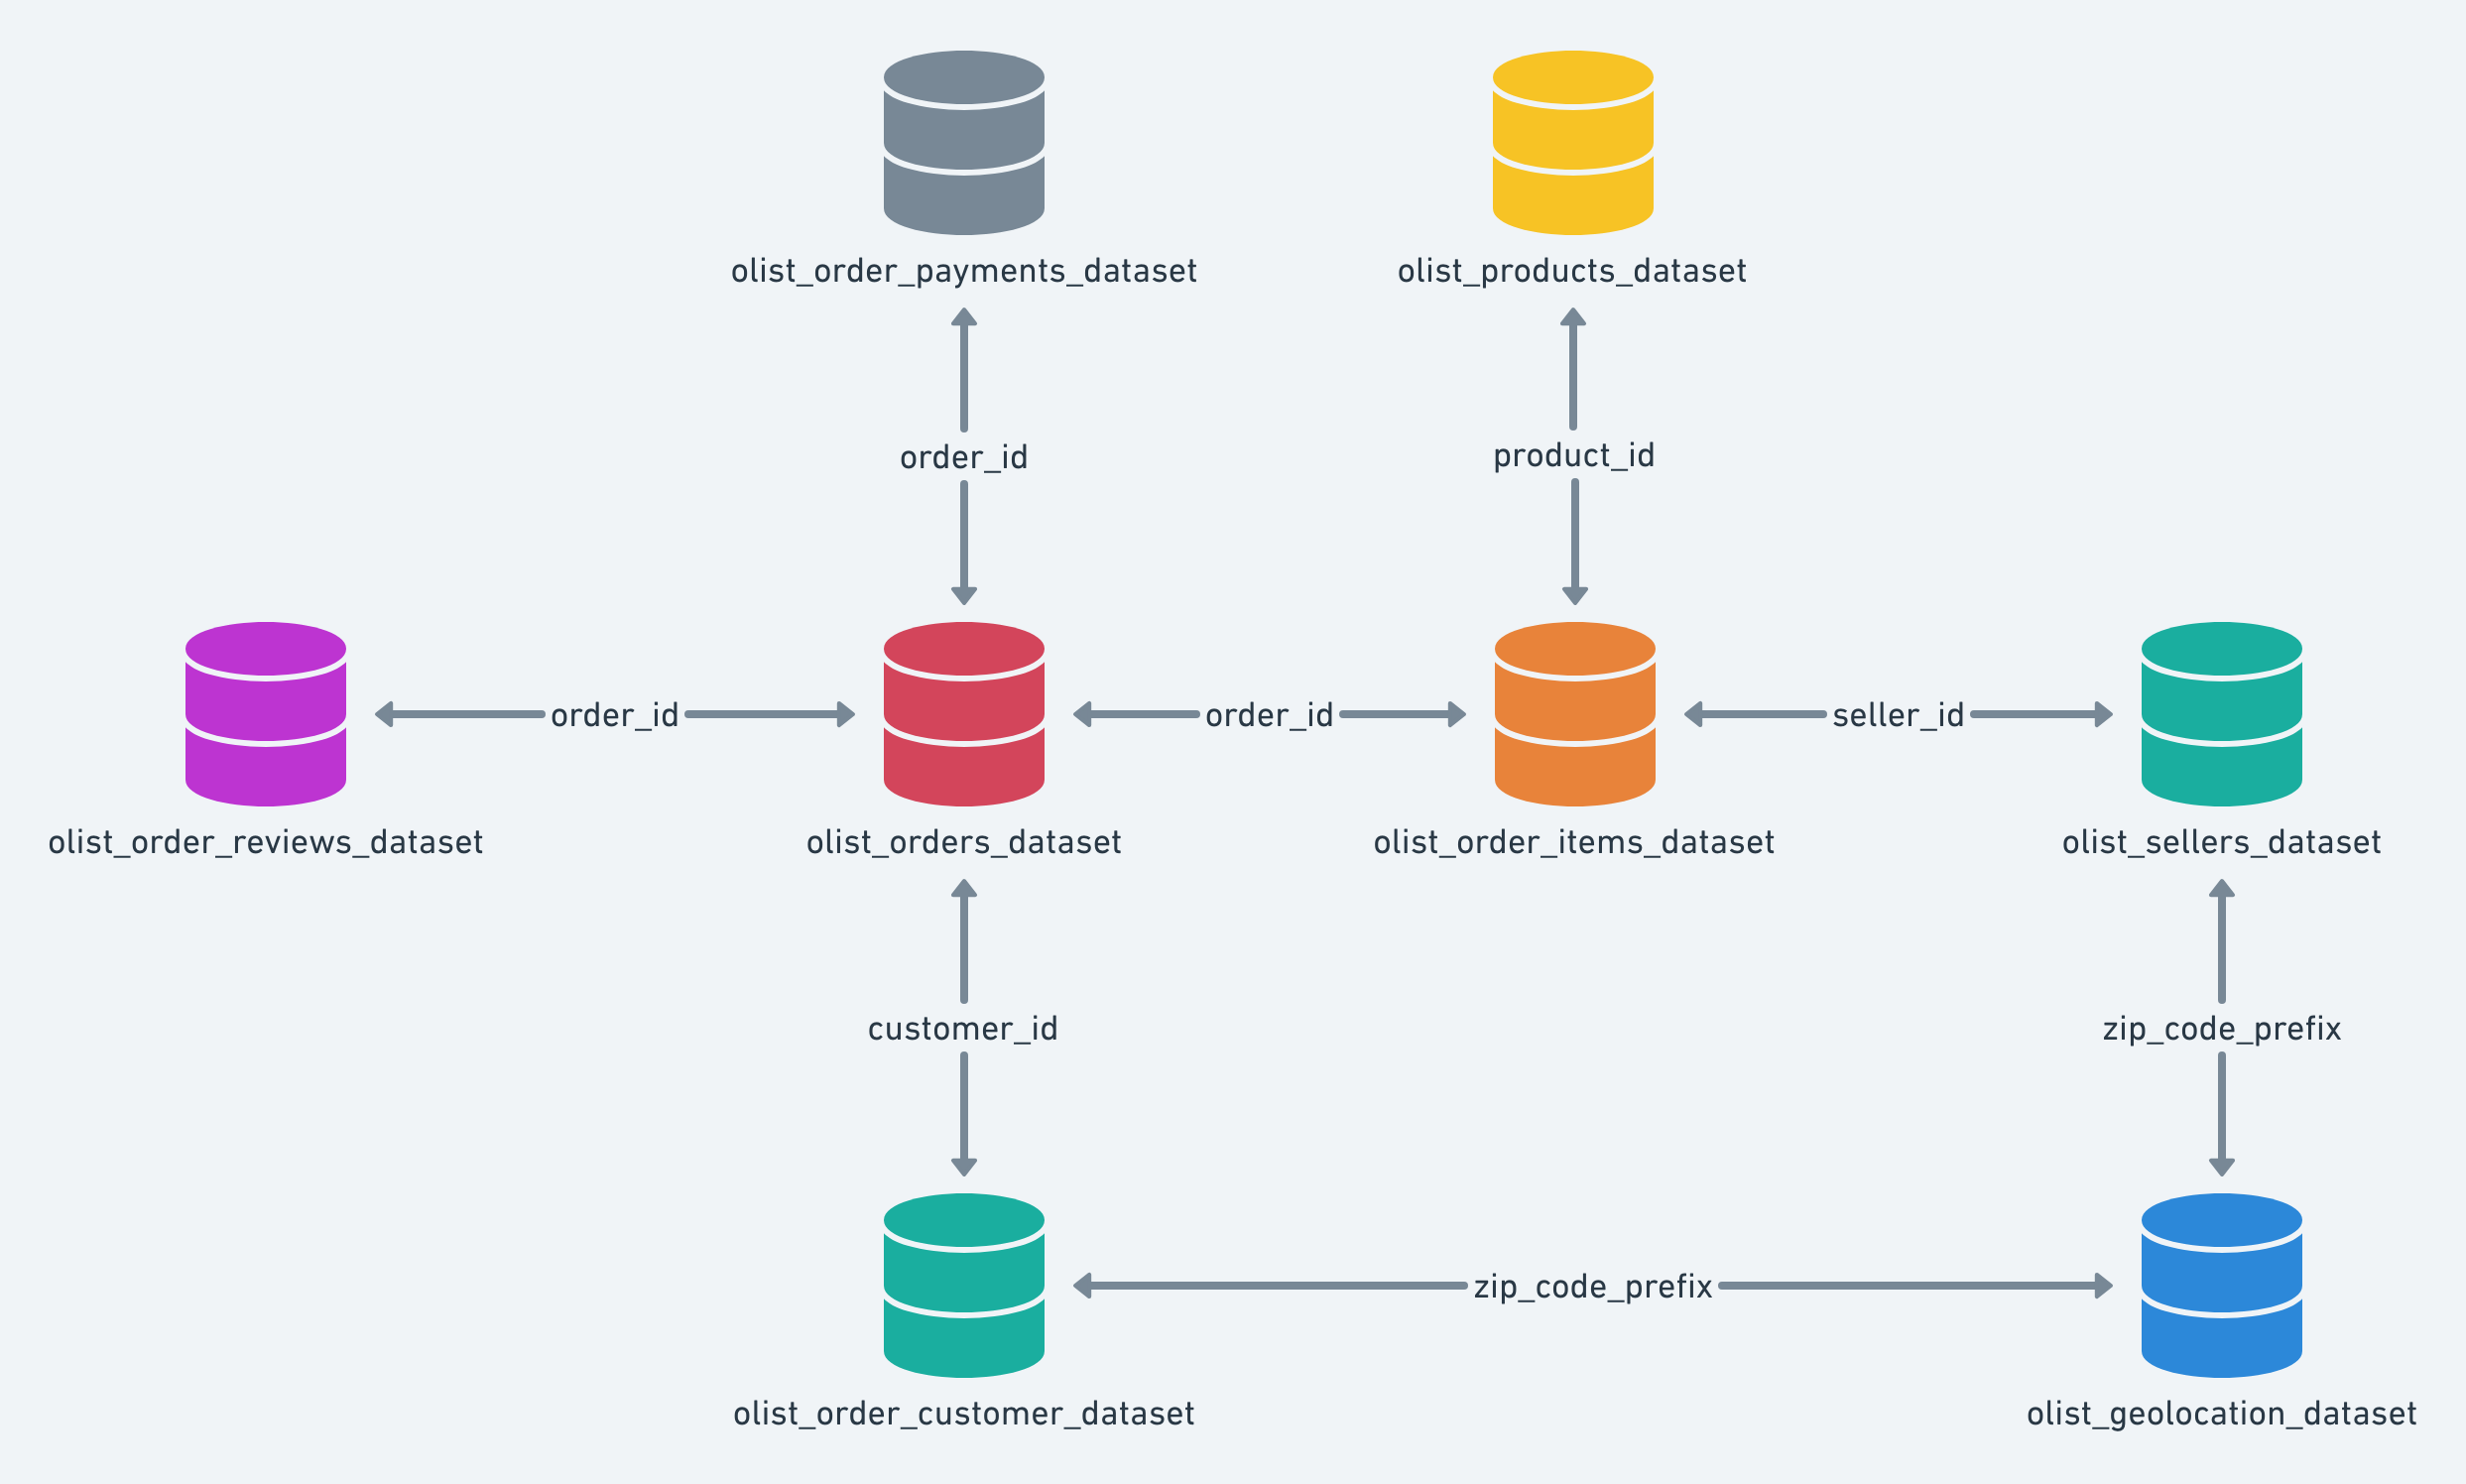

# Data Preparation

Importing Required Libraries

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

from datetime import datetime


Loading Datasets

In [10]:
customers_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_customers_dataset.csv")
orders_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_orders_dataset.csv")
products_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_products_dataset.csv")
sellers_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_sellers_dataset.csv")
order_items_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_order_items_dataset.csv")
category_translation_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/product_category_name_translation.csv")
geolocation_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_geolocation_dataset.csv")
order_reviews_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_order_reviews_dataset.csv")
order_payments_df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Brazilian_E-Commerce_EDA/src/data/olist_order_payments_dataset.csv")


Data Review

In [ ]:
customers_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [15]:
customers_df.head(10)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [16]:
orders_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [17]:
orders_df.head(10)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [22]:
products_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [23]:
products_df.head(10)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60.0,745.0,1.0,200.0,38.0,5.0,11.0
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,56.0,1272.0,4.0,18350.0,70.0,24.0,44.0
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.0,184.0,2.0,900.0,40.0,8.0,40.0
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,57.0,163.0,1.0,400.0,27.0,13.0,17.0
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,36.0,1156.0,1.0,600.0,17.0,10.0,12.0


In [24]:
sellers_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


In [25]:
sellers_df.head(10)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP
8,768a86e36ad6aae3d03ee3c6433d61df,1529,sao paulo,SP
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR


In [26]:
order_items_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [27]:
order_items_df.head(10)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40


In [28]:
category_translation_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.2 KB


In [29]:
category_translation_df.head(10)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
5,esporte_lazer,sports_leisure
6,perfumaria,perfumery
7,utilidades_domesticas,housewares
8,telefonia,telephony
9,relogios_presentes,watches_gifts


In [31]:
geolocation_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [32]:
geolocation_df.head(10)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP
5,1012,-23.547762,-46.635361,são paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP


In [33]:
order_reviews_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [34]:
order_reviews_df.head(10)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,NaN,NaN,2017-07-16 00:00:00,2017-07-18 19:30:34
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,NaN,NaN,2018-08-14 00:00:00,2018-08-14 21:36:06
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,NaN,NaN,2017-05-17 00:00:00,2017-05-18 12:05:37
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22 00:00:00,2018-05-23 16:45:47


In [35]:
order_payments_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [45]:
order_payments_df.head(10)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [48]:
order_payments_df['payment_type'].value_counts()


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [37]:
datasets = [customers_df, order_items_df, order_payments_df, order_reviews_df, 
            products_df, category_translation_df, geolocation_df, orders_df, sellers_df]
titles = [
    "customers",
    "items",
    "payments",
    "reviews",
    "products",
    "category_translation",
    "geolocation",
    "orders",
    "sellers"
]

# To gather practical information about all datasets
info_df = pd.DataFrame({},)
info_df["dataset"] = titles
info_df["cols"] = [
    ", ".join([col for col, null in df.isnull().sum().items()]) for df in datasets
]
info_df["cols_no"] = [df.shape[1] for df in datasets]
info_df["null_no"] = [df.isnull().sum().sum() for df in datasets]
info_df["null_cols_no"] = [
    len([col for col, null in df.isnull().sum().items() if null > 0]) for df in datasets
]
info_df["null_cols"] = [
    ", ".join([col for col, null in df.isnull().sum().items() if null > 0])
    for df in datasets
]


info_df.style.background_gradient(cmap="coolwarm")


,dataset,cols,cols_no,null_no,null_cols_no,null_cols
0,customers,"customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state",5,0,0,
1,items,"order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value",7,0,0,
2,payments,"order_id, payment_sequential, payment_type, payment_installments, payment_value",5,0,0,
3,reviews,"review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp",7,145903,2,"review_comment_title, review_comment_message"
4,products,"product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm",9,2448,8,"product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm"
5,category_translation,"product_category_name, product_category_name_english",2,0,0,
6,geolocation,"geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state",5,0,0,
7,orders,"order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date",8,4908,3,"order_approved_at, order_delivered_carrier_date, order_delivered_customer_date"
8,sellers,"seller_id, seller_zip_code_prefix, seller_city, seller_state",4,0,0,


# Data Cleaning

In [ ]:
filt = order_payments_df['payment_type'] == 'not_defined'
order_payments_df.loc[filt, 'payment_type'] = 'cash'
order_payments_df['payment_type'].value_counts()


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
cash               3
Name: count, dtype: int64

In [65]:
products_df.isna().sum()
products_df[products_df["product_category_name"].isna()].isna().sum()
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df['product_category_name'].value_counts()


product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 74, dtype: int64

# Questions 

Revenue by category: 
	Which product categories bring in the most revenue, and how do their average review scores compare? (orders → items → products → translation table)

In [70]:
orders_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [79]:
# valid orders only
valid_orders = orders_df.loc[~orders_df["order_status"].isin(["canceled", "unavailable"]), ["order_id",]]
# valid_orders.head(10)


# keeping only one review score per order, as one order can have multiple reviews, we will take the mean of the review scores for each order
review_per_order = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()
# review_per_order.head(10)


# products with English category names
products_with_english_categories = products_df[["product_id", "product_category_name"]].merge(category_translation_df, on="product_category_name", how="left")


products_with_english_categories["category"] = (
    products_with_english_categories["product_category_name_english"]
    .fillna(products_with_english_categories["product_category_name"])  # untranslated -> keep Portuguese name
    .fillna("unknown")  # no category at all
)
# products_with_english_categories.head(10)

# orders -> items -> products
df = (
    valid_orders
    .merge(order_items_df[["order_id", "product_id", "price"]], on="order_id", how="inner")
    .merge(products_with_english_categories[["product_id", "category"]], on="product_id", how="left",)
)

df.head(10)


,order_id,product_id,price,category
0,e481f51cbdc54678b7cc49136f2d6af7,87285b34884572647811a353c7ac498a,29.99,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,595fac2a385ac33a80bd5114aec74eb8,118.70,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,aa4383b373c6aca5d8797843e5594415,159.90,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,65266b2da20d04dbe00c5c2d3bb7859e,19.90,stationery
5,a4591c265e18cb1dcee52889e2d8acc3,060cb19345d90064d1015407193c233d,147.90,auto
6,136cce7faa42fdb2cefd53fdc79a6098,a1804276d9941ac0733cfd409f5206eb,49.90,unknown
7,6514b8ad8028c9f2cc2374ded245783f,4520766ec412348b8d4caa5e8a18c464,59.99,auto
8,76c6e866289321a7c93b82b54852dc33,ac1789e492dcd698c5c10b97a671243a,19.90,furniture_decor
9,e69bfb5eb88e0ed6a785585b27e16dbf,9a78fb9862b10749a117f7fc3c31f051,149.99,office_furniture


In [80]:
# sanity checks
print("valid orders:", len(valid_orders))
print("item rows after merge:", len(df))
print("items rows for valid orders:", order_items_df["order_id"].isin(valid_orders["order_id"]).sum())
print("total revenue:", df["price"].sum().round(2))


valid orders: 98207
item rows after merge: 112101
items rows for valid orders: 112101
total revenue: 13494400.74


In [81]:
# revenue and volume
revenue = (df.groupby("category")["price"].agg(revenue="sum", items_sold="count").reset_index())

# review score: one row per (order, category), then average
cat_order = (
    df[["order_id", "category"]]
    .drop_duplicates()
    .merge(review_per_order, on="order_id", how="left")
)
rating = (
    cat_order.groupby("category")["review_score"]
    .agg(avg_review="mean", n_reviews="count")
    .reset_index()
)

summary = (
    revenue.merge(rating, on="category")
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)
summary["revenue_share_pct"] = (
    summary["revenue"] / summary["revenue"].sum() * 100
).round(1)

top10 = summary.head(10)
top10


,category,revenue,items_sold,avg_review,n_reviews,revenue_share_pct
0,health_beauty,1255695.13,9634,4.190651,8735,9.3
1,watches_gifts,1198185.21,5970,4.074501,5557,8.9
2,bed_bath_table,1035964.06,11097,3.974233,9295,7.7
3,sports_leisure,979740.92,8590,4.183852,7623,7.3
4,computers_accessories,904322.02,7781,4.039223,6616,6.7
5,furniture_decor,727465.05,8298,4.020078,6375,5.4
6,housewares,626825.80,6915,4.158402,5808,4.6
7,cool_stuff,620770.49,3779,4.180284,3586,4.6
8,auto,586585.73,4204,4.105530,3852,4.3
9,garden_tools,481009.94,4328,4.145564,3483,3.6


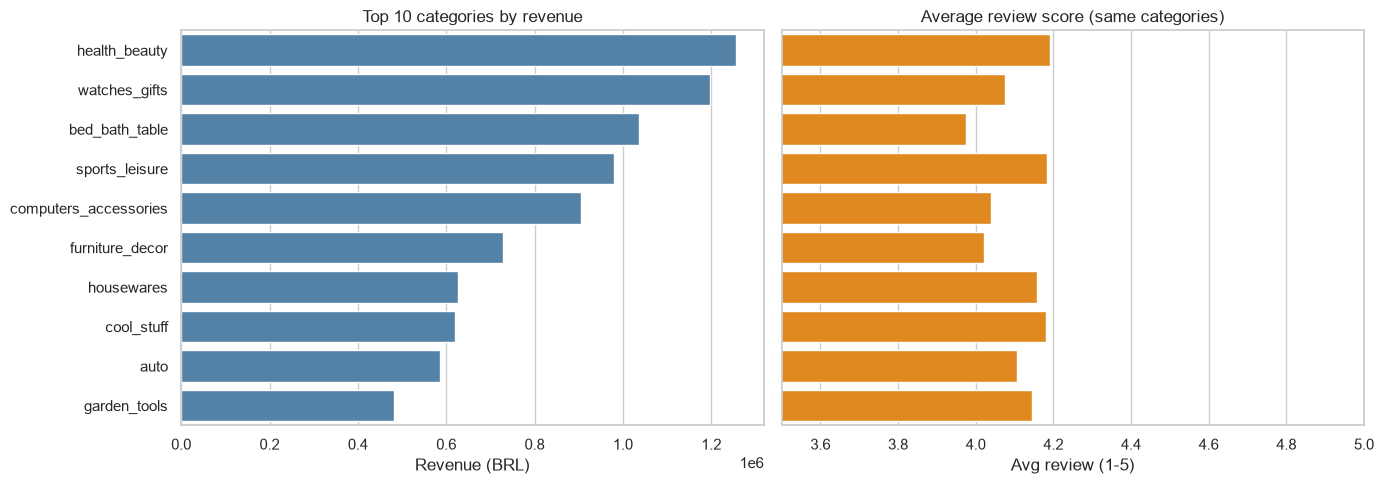

In [82]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.barplot(data=top10, y="category", x="revenue", ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 categories by revenue")
axes[0].set_xlabel("Revenue (BRL)")
axes[0].set_ylabel("")

sns.barplot(data=top10, y="category", x="avg_review", ax=axes[1], color="darkorange")
axes[1].set_title("Average review score (same categories)")
axes[1].set_xlabel("Avg review (1-5)")
axes[1].set_xlim(3.5, 5)  # zoomed axis; say so in the caption

plt.tight_layout()
plt.show()



Trend over time: 
	How do monthly orders and revenue change, and is there a seasonal peak such as Black Friday? (orders → items)

In [83]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(orders_df["order_purchase_timestamp"])

valid = orders_df.loc[~orders_df["order_status"].isin(["canceled", "unavailable"]), ["order_id", "order_purchase_timestamp"],].copy()
valid["month"] = valid["order_purchase_timestamp"].dt.to_period("M")

# orders per month (from the orders table, before any merge)
monthly_orders = valid.groupby("month")["order_id"].nunique().rename("orders")

# revenue per month (orders -> items)
rev = valid.merge(order_items_df[["order_id", "price"]], on="order_id", how="inner")
monthly_revenue = rev.groupby("month")["price"].sum().rename("revenue")

monthly = pd.concat([monthly_orders, monthly_revenue], axis=1).reset_index()
monthly["avg_order_value"] = monthly["revenue"] / monthly["orders"]
monthly["orders_mom_pct"] = monthly["orders"].pct_change().mul(100).round(1)
monthly["month_start"] = monthly["month"].dt.to_timestamp()

monthly


,month,orders,revenue,avg_order_value,orders_mom_pct,month_start
0,2016-09,2,207.86,103.930000,NaN,2016-09-01
1,2016-10,293,44507.30,151.902048,14550.0,2016-10-01
2,2016-12,1,10.90,10.900000,-99.7,2016-12-01
3,2017-01,787,120098.27,152.602630,78600.0,2017-01-01
4,2017-02,1718,244959.35,142.584022,118.3,2017-02-01
5,2017-03,2617,368341.32,140.749454,52.3,2017-03-01
6,2017-04,2377,353842.98,148.861161,-9.2,2017-04-01
7,2017-05,3640,503159.19,138.230547,53.1,2017-05-01
8,2017-06,3205,429916.61,134.139348,-12.0,2017-06-01
9,2017-07,3946,492287.30,124.756031,23.1,2017-07-01


In [84]:
window = monthly[
    (monthly["month_start"] >= "2017-01-01") & (monthly["month_start"] <= "2018-08-01")
]


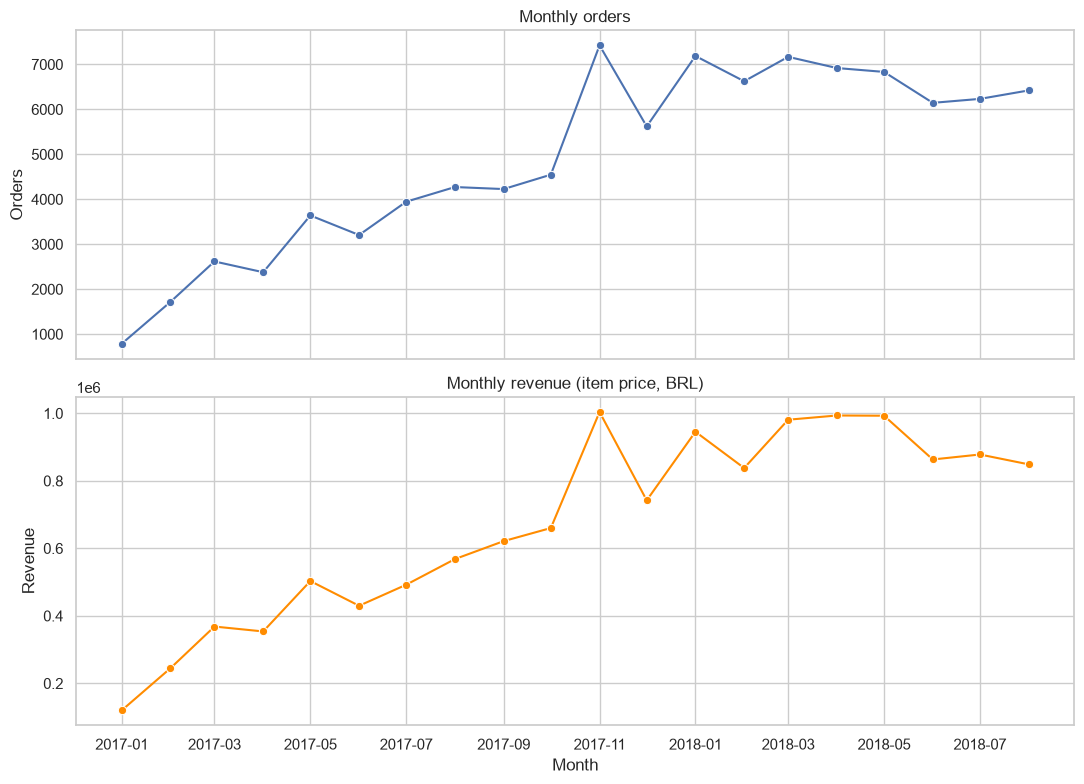

In [85]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(data=window, x="month_start", y="orders", marker="o", ax=axes[0])
axes[0].set_title("Monthly orders")
axes[0].set_xlabel("")
axes[0].set_ylabel("Orders")

sns.lineplot(
    data=window,
    x="month_start",
    y="revenue",
    marker="o",
    ax=axes[1],
    color="darkorange",
)
axes[1].set_title("Monthly revenue (item price, BRL)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue")

plt.tight_layout()
plt.show()


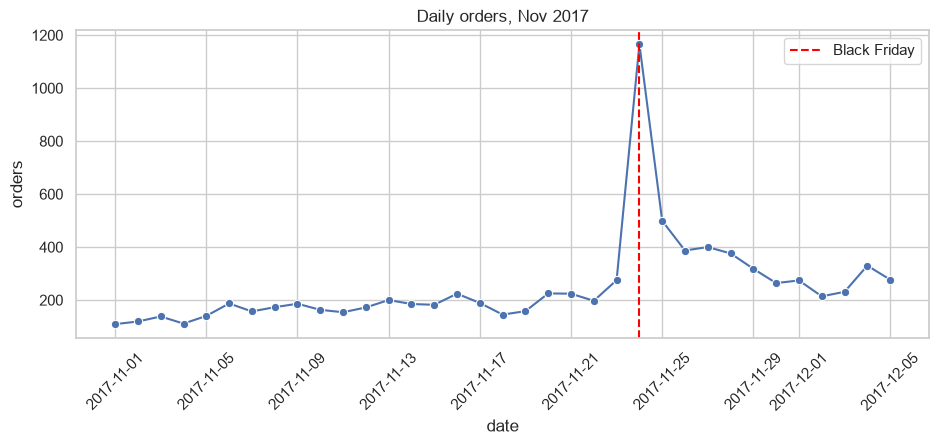

Black Friday: 1166 orders vs Oct 2017 daily average 147 (7.9x)


In [86]:
valid["date"] = valid["order_purchase_timestamp"].dt.normalize()
daily = valid.groupby("date")["order_id"].nunique().rename("orders").reset_index()

nov17 = daily[(daily["date"] >= "2017-11-01") & (daily["date"] <= "2017-12-05")]

plt.figure(figsize=(11, 4))
sns.lineplot(data=nov17, x="date", y="orders", marker="o")
plt.axvline(
    pd.Timestamp("2017-11-24"), color="red", linestyle="--", label="Black Friday"
)
plt.legend()
plt.title("Daily orders, Nov 2017")
plt.xticks(rotation=45)
plt.show()

# how much bigger was it than a normal day?
baseline = daily[(daily["date"] >= "2017-10-01") & (daily["date"] <= "2017-10-31")][
    "orders"
].mean()
bf = daily.loc[daily["date"] == "2017-11-24", "orders"].iloc[0]
print(
    f"Black Friday: {bf} orders vs Oct 2017 daily average {baseline:.0f} ({bf / baseline:.1f}x)"
)


Delivery and satisfaction: 
	Do late deliveries get lower review scores? (orders → reviews; compare delivered date against estimated date)

In [87]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    orders_df[c] = pd.to_datetime(orders_df[c])

delivered = orders_df.loc[
    (orders_df["order_status"] == "delivered")
    & orders_df["order_delivered_customer_date"].notna()
].copy()

delivered["delivered_date"] = delivered["order_delivered_customer_date"].dt.normalize()
delivered["estimated_date"] = delivered["order_estimated_delivery_date"].dt.normalize()
delivered["days_vs_estimate"] = (
    delivered["delivered_date"] - delivered["estimated_date"]
).dt.days
delivered["is_late"] = delivered["days_vs_estimate"] > 0
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.days

# latest review per order
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])
latest_review = order_reviews_df.sort_values("review_answer_timestamp").drop_duplicates(
    "order_id", keep="last"
)[["order_id", "review_score", "review_creation_date"]]

df = delivered.merge(latest_review, on="order_id", how="inner")

# sanity checks
print("delivered orders:", len(delivered))
print("with a review:", len(df))
print("duplicate orders after merge:", df["order_id"].duplicated().sum())  # should be 0
print("share late:", df["is_late"].mean().round(3))


delivered orders: 96470
with a review: 95824
duplicate orders after merge: 0
share late: 0.067


In [88]:
# Late vs On Time
comparison = (
    df.groupby("is_late")["review_score"]
    .agg(avg_score="mean", median_score="median", n_orders="count")
    .round(2)
)

comparison["pct_1_star"] = (
    df.groupby("is_late")["review_score"]
    .apply(lambda s: (s == 1).mean() * 100)
    .round(1)
)
comparison["pct_5_star"] = (
    df.groupby("is_late")["review_score"]
    .apply(lambda s: (s == 5).mean() * 100)
    .round(1)
)
comparison


,avg_score,median_score,n_orders,pct_1_star,pct_5_star
is_late,,,,,
False,4.29,5.0,89443,6.6,62.3
True,2.27,1.0,6381,53.8,16.5


In [89]:
df["lateness_bucket"] = pd.cut(
    df["days_vs_estimate"],
    bins=[-float("inf"), 0, 3, 7, 14, float("inf")],
    labels=[
        "On time / early",
        "1-3 days late",
        "4-7 days late",
        "8-14 days late",
        "15+ days late",
    ],
)

bucket_summary = (
    df.groupby("lateness_bucket", observed=True)["review_score"]
    .agg(avg_score="mean", n_orders="count")
    .round(2)
)
bucket_summary


,avg_score,n_orders
lateness_bucket,,
On time / early,4.29,89443
1-3 days late,3.29,1852
4-7 days late,2.10,1748
8-14 days late,1.67,1446
15+ days late,1.72,1335


In [91]:
from scipy.stats import mannwhitneyu

late = df.loc[df["is_late"], "review_score"]
ontime = df.loc[~df["is_late"], "review_score"]
print(mannwhitneyu(late, ontime, alternative="less"))


MannwhitneyuResult(statistic=np.float64(103305546.0), pvalue=np.float64(0.0))


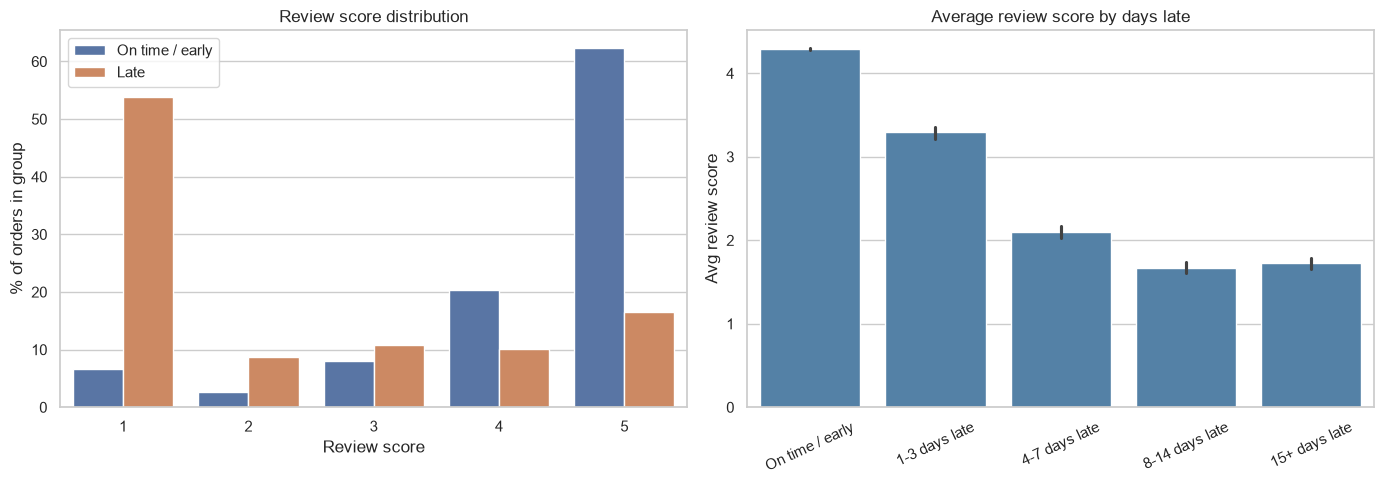

In [92]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# score distribution, late vs on time (as percentages, since the groups are very unequal in size)
dist = (
    df.groupby("is_late")["review_score"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("pct")
    .reset_index()
)
dist["is_late"] = dist["is_late"].map({False: "On time / early", True: "Late"})
sns.barplot(data=dist, x="review_score", y="pct", hue="is_late", ax=axes[0])
axes[0].set_title("Review score distribution")
axes[0].set_xlabel("Review score")
axes[0].set_ylabel("% of orders in group")
axes[0].legend(title="")

# average score by lateness bucket
sns.barplot(
    data=df, x="lateness_bucket", y="review_score", ax=axes[1], color="steelblue"
)
axes[1].set_title("Average review score by days late")
axes[1].set_xlabel("")
axes[1].set_ylabel("Avg review score")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


In [93]:
# reviews written before the item arrived (review may reflect something other than lateness)
df["review_creation_date"] = pd.to_datetime(df["review_creation_date"])
print(
    "reviews created before delivery:",
    (df["review_creation_date"] < df["order_delivered_customer_date"]).mean().round(3),
)


reviews created before delivery: 0.085


Regional delivery speed: 
	Which customer states have the slowest average delivery times? (orders → customers)

In [94]:
for c in [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]:
    orders_df[c] = pd.to_datetime(orders_df[c])

delivered = orders_df.loc[
    (orders_df["order_status"] == "delivered")
    & orders_df["order_delivered_customer_date"].notna(),
    [
        "order_id",
        "customer_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df = delivered.merge(customers_df[["customer_id", "customer_state"]], on="customer_id", how="left")

# sanity checks
print("delivered orders:", len(delivered))
print("after merge:", len(df))  # should be equal
print("missing state:", df["customer_state"].isna().sum())  # should be 0
print(df["delivery_days"].describe().round(1))


delivered orders: 96470
after merge: 96470
missing state: 0
count    96470.0
mean        12.6
std          9.5
min          0.5
25%          6.8
50%         10.2
75%         15.7
max        209.6
Name: delivery_days, dtype: float64


In [95]:
df["is_late"] = (
    df["order_delivered_customer_date"].dt.normalize()
    > df["order_estimated_delivery_date"].dt.normalize()
)

state_summary = (
    df.groupby("customer_state")
    .agg(
        orders=("order_id", "count"),
        mean_days=("delivery_days", "mean"),
        median_days=("delivery_days", "median"),
        p90_days=("delivery_days", lambda s: s.quantile(0.9)),
        pct_late=("is_late", lambda s: s.mean() * 100),
    )
    .round(1)
    .sort_values("median_days", ascending=False)
    .reset_index()
)

MIN_ORDERS = 100
ranked = state_summary[state_summary["orders"] >= MIN_ORDERS]

print(
    "states excluded for low volume:",
    state_summary.loc[state_summary["orders"] < MIN_ORDERS, "customer_state"].tolist(),
)
ranked.head(10)  # slowest
ranked.tail(5)  # fastest


states excluded for low volume: ['RR', 'AP', 'AC']


,customer_state,orders,mean_days,median_days,p90_days,pct_late
22,RJ,12350,15.3,12.0,29.1,12.1
23,DF,2080,13.0,11.4,21.6,5.7
24,PR,4923,12.0,10.4,20.1,4.0
25,MG,11354,12.0,10.3,20.2,4.6
26,SP,40494,8.8,7.2,15.8,4.5


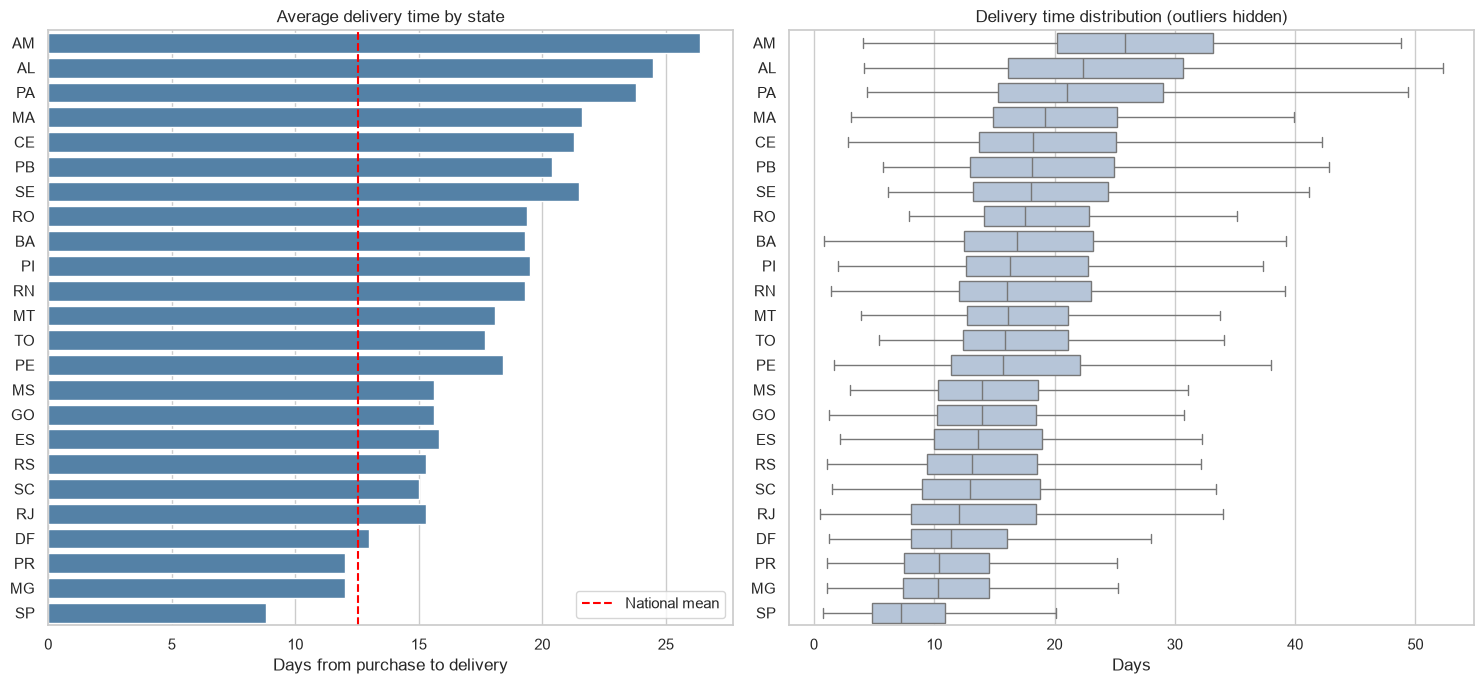

In [96]:
sns.set_theme(style="whitegrid")
order_idx = ranked.sort_values("median_days", ascending=False)["customer_state"]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

sns.barplot(
    data=ranked,
    y="customer_state",
    x="mean_days",
    order=order_idx,
    ax=axes[0],
    color="steelblue",
)
axes[0].axvline(
    df["delivery_days"].mean(), color="red", linestyle="--", label="National mean"
)
axes[0].set_title("Average delivery time by state")
axes[0].set_xlabel("Days from purchase to delivery")
axes[0].set_ylabel("")
axes[0].legend()

sns.boxplot(
    data=df[df["customer_state"].isin(order_idx)],
    y="customer_state",
    x="delivery_days",
    order=order_idx,
    showfliers=False,
    ax=axes[1],
    color="lightsteelblue",
)
axes[1].set_title("Delivery time distribution (outliers hidden)")
axes[1].set_xlabel("Days")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


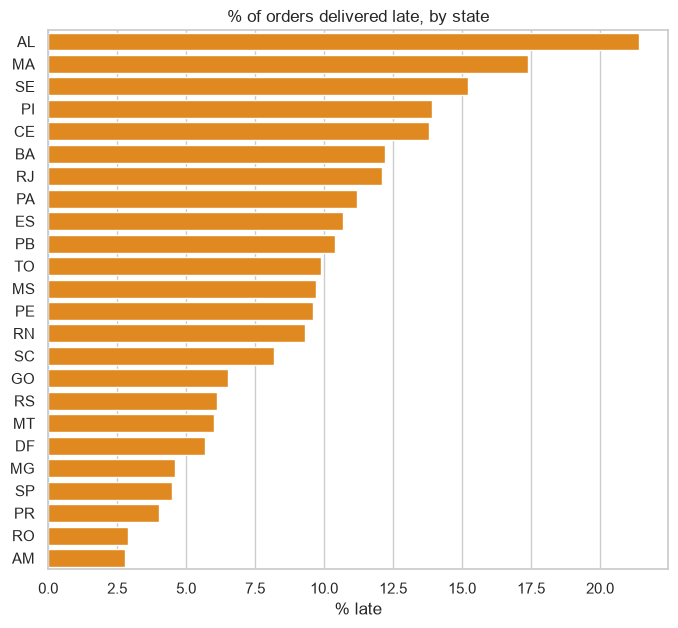

In [97]:
plt.figure(figsize=(8, 7))
sns.barplot(
    data=ranked.sort_values("pct_late", ascending=False),
    y="customer_state",
    x="pct_late",
    color="darkorange",
)
plt.title("% of orders delivered late, by state")
plt.xlabel("% late")
plt.ylabel("")
plt.show()


Payments: 
	How do payment type and installments relate to order value? (orders → payments)

In [ ]:
valid = orders_df.loc[
    ~orders_df["order_status"].isin(["canceled", "unavailable"]), ["order_id"]
]

pay = order_payments_df.merge(valid, on="order_id", how="inner")
pay = pay[pay["payment_type"] != "not_defined"]

# how many payment rows per order?
print(pay.groupby("order_id").size().value_counts().head())

# primary payment = largest payment in the order
primary = (
    pay.sort_values("payment_value", ascending=False)
    .drop_duplicates("order_id")[["order_id", "payment_type", "payment_installments"]]
    .rename(
        columns={
            "payment_type": "primary_type",
            "payment_installments": "primary_installments",
        }
    )
)

order_pay = (
    pay.groupby("order_id")
    .agg(
        order_value=("payment_value", "sum"),
        n_payments=("payment_sequential", "count"),
        n_types=("payment_type", "nunique"),
    )
    .reset_index()
    .merge(primary, on="order_id")
)

# sanity checks
print("orders:", len(order_pay), "| unique:", order_pay["order_id"].nunique())  # should match
print("orders with >1 payment type:", (order_pay["n_types"] > 1).mean().round(3))
print(order_pay["order_value"].describe().round(1))


1    95286
2     2350
3      299
4      106
5       52
Name: count, dtype: int64
orders: 98206 | unique: 98206
orders with >1 payment type: 0.023
count    98206.0
mean       160.3
std        219.1
min          9.6
25%         62.0
50%        105.3
75%        176.8
max      13664.1
Name: order_value, dtype: float64


In [ ]:
#Payment Type vs Order Value
type_summary = (
    order_pay.groupby("primary_type")["order_value"]
    .agg(orders="count", mean_value="mean", median_value="median", total_value="sum")
    .round(1)
)
type_summary["pct_orders"] = (type_summary["orders"] / type_summary["orders"].sum() * 100).round(1)
type_summary["pct_value"] = (type_summary["total_value"] / type_summary["total_value"].sum() * 100).round(1)
type_summary.sort_values("orders", ascending=False)


,orders,mean_value,median_value,total_value,pct_orders,pct_value
primary_type,,,,,,
credit_card,74116,166.6,109.5,12350903.3,75.5,78.5
boleto,19539,144.7,93.8,2826802.3,19.9,18.0
voucher,3037,114.9,81.5,349063.7,3.1,2.2
debit_card,1514,140.3,89.4,212367.8,1.5,1.3


In [100]:
from scipy.stats import spearmanr

cc = order_pay[
    (order_pay["primary_type"] == "credit_card")
    & (order_pay["n_payments"] == 1)
    & (order_pay["primary_installments"] >= 1)
].copy()

cc["inst_bucket"] = pd.cut(
    cc["primary_installments"],
    bins=[0, 1, 3, 6, 9, 12, 24],
    labels=["1", "2-3", "4-6", "7-9", "10-12", "13+"],
)

inst_summary = (
    cc.groupby("inst_bucket", observed=True)["order_value"]
    .agg(orders="count", median_value="median", mean_value="mean")
    .round(1)
)
print(inst_summary)

rho, p = spearmanr(cc["primary_installments"], cc["order_value"])
print(f"Spearman rho = {rho:.2f}")


             orders  median_value  mean_value
inst_bucket                                  
1             23478          71.3       100.5
2-3           22103         111.4       134.9
4-6           15745         128.0       181.3
7-9            6351         180.2       266.8
10-12          5269         236.3       407.0
13+             175         250.9       417.1
Spearman rho = 0.46


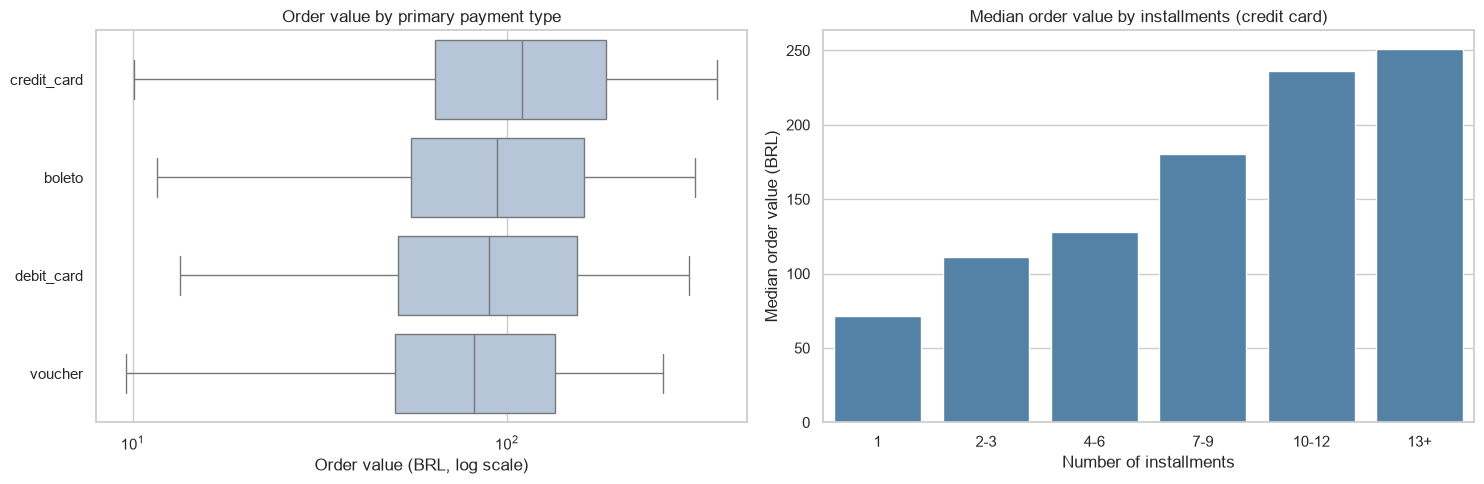

In [101]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# order value by payment type (log scale because of the long tail)
order_idx = type_summary.sort_values("median_value", ascending=False).index
sns.boxplot(
    data=order_pay,
    y="primary_type",
    x="order_value",
    order=order_idx,
    showfliers=False,
    ax=axes[0],
    color="lightsteelblue",
)
axes[0].set_xscale("log")
axes[0].set_title("Order value by primary payment type")
axes[0].set_xlabel("Order value (BRL, log scale)")
axes[0].set_ylabel("")

# median order value by installment bucket
sns.barplot(
    data=cc,
    x="inst_bucket",
    y="order_value",
    estimator="median",
    errorbar=None,
    ax=axes[1],
    color="steelblue",
)
axes[1].set_title("Median order value by installments (credit card)")
axes[1].set_xlabel("Number of installments")
axes[1].set_ylabel("Median order value (BRL)")

plt.tight_layout()
plt.show()


In [102]:
# are installments just a function of price tiers?
cc["value_band"] = pd.qcut(
    cc["order_value"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]
)
pd.crosstab(cc["value_band"], cc["inst_bucket"], normalize="index").mul(100).round(1)


inst_bucket,1,2-3,4-6,7-9,10-12,13+
value_band,,,,,,
Q1 low,58.2,28.1,13.6,0.0,0.0,0.0
Q2,42.7,30.5,19.5,7.2,0.0,0.0
Q3,29.4,33.3,23.3,7.8,6.2,0.0
Q4,18.6,39.1,22.4,10.5,9.1,0.4
Q5 high,11.6,20.1,28.8,17.9,20.8,0.8



Sellers: 
	Do high-volume sellers get better or worse reviews? (items → sellers → reviews)

In [103]:
valid = orders_df.loc[
    ~orders_df["order_status"].isin(["canceled", "unavailable"]), ["order_id"]
]

review_per_order = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()

# one row per (order, seller)
order_seller = (
    order_items_df[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(valid, on="order_id", how="inner")
)

# sanity checks
print(
    "seller ids missing from sellers table:",
    (~order_seller["seller_id"].isin(sellers_df["seller_id"])).sum(),
)
multi = order_seller.groupby("order_id")["seller_id"].nunique()
print("share of orders with >1 seller:", (multi > 1).mean().round(4))

# volume uses all valid orders; rating uses reviewed orders
volume = order_seller.groupby("seller_id")["order_id"].nunique().rename("orders")

rating = (
    order_seller.merge(review_per_order, on="order_id", how="inner")
    .groupby("seller_id")["review_score"]
    .agg(avg_review="mean", n_reviews="count")
)

seller_df = (
    volume.to_frame()
    .join(rating, how="inner")
    .reset_index()
    .merge(sellers_df[["seller_id", "seller_state"]], on="seller_id", how="left")
)

seller_df["pct_low"] = (
    order_seller.merge(review_per_order, on="order_id")
    .assign(low=lambda d: d["review_score"] <= 2)
    .groupby("seller_id")["low"]
    .mean()
    .mul(100)
    .reindex(seller_df["seller_id"])
    .values
)

print("sellers:", len(seller_df))
print(seller_df["orders"].describe().round(1))


seller ids missing from sellers table: 0
share of orders with >1 seller: 0.013
sellers: 3049
count    3049.0
mean       32.6
std       105.6
min         1.0
25%         2.0
50%         7.0
75%        22.0
max      1847.0
Name: orders, dtype: float64


In [104]:
#Volume Tiers

seller_df["tier"] = pd.cut(
    seller_df["orders"],
    bins=[0, 4, 19, 49, 99, float("inf")],
    labels=["1-4", "5-19", "20-49", "50-99", "100+"],
)

MIN_REVIEWS = 10
reliable = seller_df[seller_df["n_reviews"] >= MIN_REVIEWS]

tier_summary = (
    seller_df.groupby("tier", observed=True)
    .agg(
        sellers=("seller_id", "count"),
        total_orders=("orders", "sum"),
        mean_seller_avg=("avg_review", "mean"),
        median_seller_avg=("avg_review", "median"),
    )
    .round(2)
)

# order-weighted: what the average customer of each tier experiences
tier_summary["order_weighted_avg"] = (
    seller_df.assign(w=seller_df["avg_review"] * seller_df["n_reviews"])
    .groupby("tier", observed=True)
    .apply(lambda g: g["w"].sum() / g["n_reviews"].sum())
    .round(2)
)
tier_summary["pct_orders"] = (
    tier_summary["total_orders"] / tier_summary["total_orders"].sum() * 100
).round(1)
tier_summary


,sellers,total_orders,mean_seller_avg,median_seller_avg,order_weighted_avg,pct_orders
tier,,,,,,
1-4,1266,2505,3.94,4.50,3.99,2.5
5-19,969,9637,4.14,4.22,4.13,9.7
20-49,386,12183,4.15,4.18,4.15,12.2
50-99,218,15402,4.12,4.16,4.12,15.5
100+,210,59811,4.10,4.13,4.08,60.1


In [ ]:
#Correlation
from scipy.stats import spearmanr

rho, p = spearmanr(reliable["orders"], reliable["avg_review"])
print(f"Spearman rho (sellers with >= {MIN_REVIEWS} reviews, n={len(reliable)}): {rho:.2f}")


Spearman rho (sellers with >= 10 reviews, n=1259): -0.07


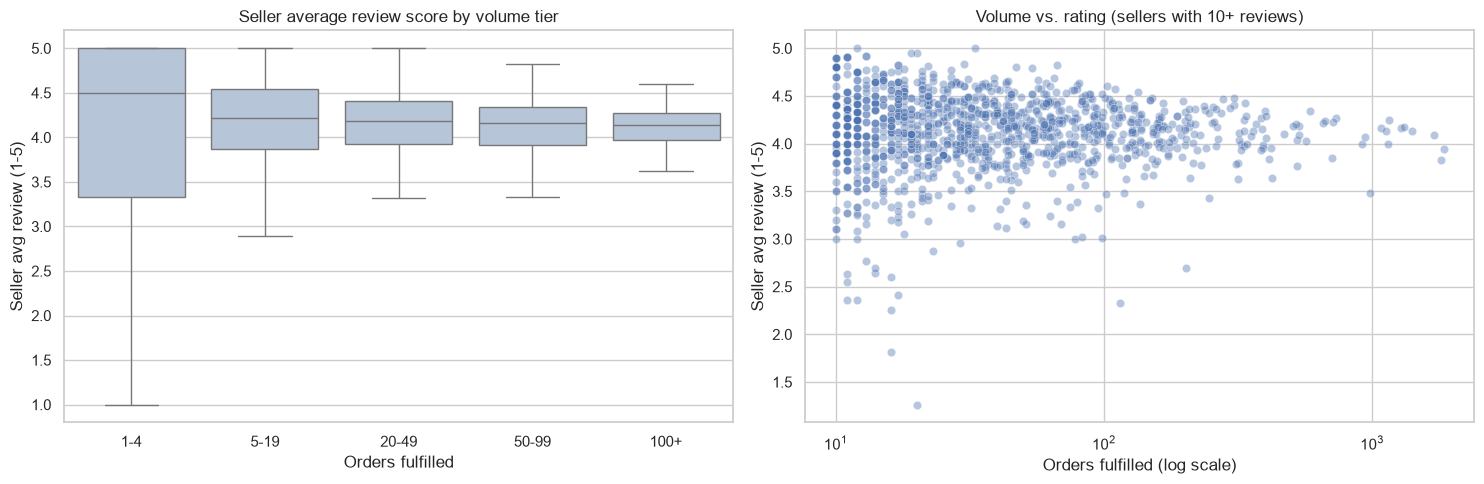

In [106]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=seller_df, x="tier", y="avg_review", showfliers=False,
            ax=axes[0], color="lightsteelblue")
axes[0].set_title("Seller average review score by volume tier")
axes[0].set_xlabel("Orders fulfilled")
axes[0].set_ylabel("Seller avg review (1-5)")

sns.scatterplot(data=reliable, x="orders", y="avg_review", alpha=0.4, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title(f"Volume vs. rating (sellers with {MIN_REVIEWS}+ reviews)")
axes[1].set_xlabel("Orders fulfilled (log scale)")
axes[1].set_ylabel("Seller avg review (1-5)")

plt.tight_layout()
plt.show()


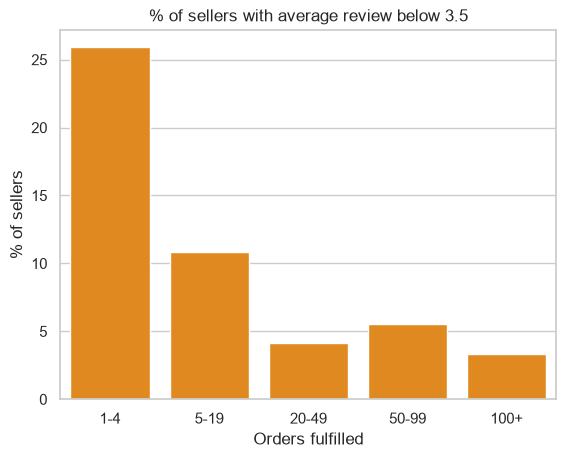

In [107]:
bad = (seller_df.assign(poor=seller_df["avg_review"] < 3.5)
                .groupby("tier", observed=True)["poor"].mean().mul(100).reset_index())
sns.barplot(data=bad, x="tier", y="poor", color="darkorange")
plt.title("% of sellers with average review below 3.5")
plt.ylabel("% of sellers"); plt.xlabel("Orders fulfilled")
plt.show()


In [ ]:
#Single-seller orders only, to remove the attribution problem

single_ids = multi[multi == 1].index
single = (
    order_seller[order_seller["order_id"].isin(single_ids)]
    .merge(review_per_order, on="order_id")
    .groupby("seller_id")["review_score"]
    .agg(avg_review="mean", n_reviews="count")
    .join(volume)
    .query("n_reviews >= @MIN_REVIEWS")
)
print(spearmanr(single["orders"], single["avg_review"]))



SignificanceResult(statistic=np.float64(-0.07033411304207156), pvalue=np.float64(0.01338779832684414))


In [ ]:
#Late deliveries as a possible driver, linking back to Q3: 

d = orders_df.loc[
    orders_df["order_status"] == "delivered",
    ["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"],
].dropna()
d["is_late"] = (
    pd.to_datetime(d["order_delivered_customer_date"]).dt.normalize()
    > pd.to_datetime(d["order_estimated_delivery_date"]).dt.normalize()
)

late_by_seller = (
    order_seller.merge(d[["order_id", "is_late"]], on="order_id")
    .groupby("seller_id")["is_late"]
    .mean()
    .mul(100)
    .rename("pct_late")
)
tier_late = (
    seller_df.merge(late_by_seller, on="seller_id")
    .groupby("tier", observed=True)["pct_late"]
    .mean()
    .round(1)
)
tier_late


tier
1-4      7.2
5-19     6.6
20-49    6.5
50-99    6.8
100+     6.4
Name: pct_late, dtype: float64